# 12 Faster-moving reference level, 09:00 cutoff

Notebooks 10 and 11 showed that the models under-forecast when the price level rises, and that the 28-day median reference lags. Here the deviation target is built from a faster-moving reference, so the weather effect rides on a reference that tracks the level better. Three references (all from prices known at the cutoff):

- `ref28`: 28-day same-period median (the baseline used so far).
- `ref7`: 7-day same-period median.
- `refshift`: `ref28` shifted by the change in overall level, `level7 - level28` (the shape of the 28-day profile, the level of the last 7 days).

For each reference: the reference alone as a forecast, a Huber model (as in 11, alpha 30) and the gradient boosting model (as in 07) predicting the deviation from it. Folds, metrics and the early/recent split as before.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
D9["ref28"] = D9["med28_same"]
D9["ref7"] = D9["med7_same"]
D9["refshift"] = D9["med28_same"] + D9["level7"] - D9["level28"]
REFS = ["ref28", "ref7", "refshift"]

days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
VAL = D9["day"].isin(val_days_all)
COMMON = D9[REFS].notna().all(axis=1) & D9["price"].notna()      # score every method on the same rows
print(int(VAL.sum()), "validation rows;", int((VAL & COMMON).sum()), "scored (all three references available)")

22847 validation rows; 22847 scored (all three references available)


## 1. References on their own

Each reference used directly as the forecast, on the common rows. Differences to `ref28` are mean per-fold differences; 'late' means folds 13-16.

In [2]:
def fold_table(pred):
    rows = []
    for f in folds:
        d = D9[D9["day"].isin(f["val_days"]) & COMMON].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

FT = {f"{r} alone": fold_table(D9[r]) for r in REFS}
BASE = FT["ref28 alone"]

def row(ft):
    d = {m: ft[m] - BASE[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
    return {"MAE all": ft["MAE"].mean(), "MAE late": ft["MAE"].loc[13:].mean(),
            "dMAE all": d["MAE"].mean(), "dMAE 0-12": d["MAE"].loc[:12].mean(), "dMAE late": d["MAE"].loc[13:].mean(),
            "dRMSE all": d["RMSE"].mean(), "dRMSE late": d["RMSE"].loc[13:].mean(),
            "dHitTop all": d["hit_top8"].mean(), "dHitTop late": d["hit_top8"].loc[13:].mean(),
            "dHitBot all": d["hit_bot8"].mean(), "dHitBot late": d["hit_bot8"].loc[13:].mean(),
            "bias f16": ft["bias"].loc[16], "bias late": ft["bias"].loc[13:].mean()}
print(pd.DataFrame({k: row(v) for k, v in FT.items()}).T.round(3).to_string())

                MAE all  MAE late  dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop all  dHitTop late  dHitBot all  dHitBot late  bias f16  bias late
ref28 alone      30.203    31.278     0.000      0.000      0.000      0.000       0.000        0.000         0.000        0.000         0.000    -6.747     -0.678
ref7 alone       32.148    33.026     1.945      2.006      1.748      2.463       2.350       -0.052        -0.059       -0.051        -0.068     0.918      2.185
refshift alone   30.479    31.321     0.276      0.348      0.043      0.107       0.104        0.000         0.000        0.000         0.000    -0.152      1.766


## 2. Models on the deviation from each reference

Huber (alpha 30) with the spline pipeline from 11, and gradient boosting (set C, 15 leaves, 100 rows per leaf, 300 trees, absolute loss) from 07. Training rows need a price and the reference. The forecast is the reference plus the predicted deviation.

In [3]:
SPL = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
LVL = ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"]
MGN = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
OTH = ["bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
LIN = SPL + LVL + MGN + OTH + ["hour_frac", "weekday"]
CAL = ["hour_frac", "weekday", "is_weekend", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
HIST = ["d2_same", "med7_same", "med28_same", "level7", "level28", "level24h", "level_gap"]
FC = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw", "wind_total_mw",
      "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"]
GBM_COLS = CAL + HIST + FC + MGN

def make_huber():
    pre = ColumnTransformer([
        ("spl", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(n_knots=6, degree=3, extrapolation="linear"), StandardScaler()), SPL),
        ("hour", SplineTransformer(knots=np.linspace(0, 24, 13).reshape(-1, 1), degree=3, extrapolation="periodic"), ["hour_frac"]),
        ("lvl", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), LVL + MGN),
        ("oth", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), OTH),
        ("wd", OneHotEncoder(handle_unknown="ignore"), ["weekday"])])
    return Pipeline([("pre", pre), ("est", HuberRegressor(alpha=30, epsilon=1.35, max_iter=300))])

def make_gbm():
    return HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=100, l2_regularization=1.0, early_stopping=False, random_state=0)

def run_cv(kind, ref):
    pred = pd.Series(np.nan, index=D9.index)
    cols = LIN if kind == "huber" else GBM_COLS
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & D9["price"].notna() & D9[ref].notna()]
        va = D9[D9["day"].isin(f["val_days"])]
        m = (make_huber() if kind == "huber" else make_gbm()).fit(tr[cols], tr["price"] - tr[ref])
        pred.loc[va.index] = m.predict(va[cols]) + va[ref].to_numpy()
    return pred

PRED = {}
t0 = time.time()
for kind in ["huber", "gbm"]:
    for ref in REFS:
        name = f"{kind} on {ref}"
        PRED[name] = run_cv(kind, ref)
        FT[name] = fold_table(PRED[name])
        print(f"{name:20s} {time.time() - t0:5.0f}s")
P = pd.DataFrame(PRED)
for c in ["day", "period_start", "price"] + REFS:
    P[c] = D9[c]
P.loc[VAL].to_parquet("outputs/cv_preds_reference_0900.parquet", index=False)

huber on ref28           8s


huber on ref7           15s


huber on refshift       23s


gbm on ref28            37s


gbm on ref7             54s


gbm on refshift         70s


## 3. All methods against the 28-day median baseline

In [4]:
R = pd.DataFrame({k: row(v) for k, v in FT.items()}).T
print(R.round(3).to_string())

                   MAE all  MAE late  dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop all  dHitTop late  dHitBot all  dHitBot late  bias f16  bias late
ref28 alone         30.203    31.278     0.000      0.000      0.000      0.000       0.000        0.000         0.000        0.000         0.000    -6.747     -0.678
ref7 alone          32.148    33.026     1.945      2.006      1.748      2.463       2.350       -0.052        -0.059       -0.051        -0.068     0.918      2.185
refshift alone      30.479    31.321     0.276      0.348      0.043      0.107       0.104        0.000         0.000        0.000         0.000    -0.152      1.766
huber on ref28      28.298    31.043    -1.905     -2.418     -0.235     -4.123      -1.820        0.032         0.008        0.049         0.004   -15.352    -11.773
huber on ref7       28.376    31.301    -1.826     -2.395      0.023     -4.050      -1.439        0.031         0.010        0.037        -0.011   -16.331    -12.31

## 4. Each model against its own reference

Does the weather model add anything on top of the reference it is built on? Paired per-fold difference (model minus its own reference alone), all folds and late folds.

In [5]:
rows = {}
for name in PRED:
    ref = name.split(" on ")[1]
    own = FT[f"{ref} alone"]
    ft = FT[name]
    d = {m: ft[m] - own[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
    rows[name] = {"dMAE all": f"{d['MAE'].mean():+.2f} +/- {d['MAE'].std() / np.sqrt(17):.2f}", "dMAE late": f"{d['MAE'].loc[13:].mean():+.2f}",
                  "dRMSE all": f"{d['RMSE'].mean():+.2f}", "dRMSE late": f"{d['RMSE'].loc[13:].mean():+.2f}",
                  "dHitTop all": f"{d['hit_top8'].mean():+.3f}", "dHitBot all": f"{d['hit_bot8'].mean():+.3f}",
                  "dHitTop late": f"{d['hit_top8'].loc[13:].mean():+.3f}", "dHitBot late": f"{d['hit_bot8'].loc[13:].mean():+.3f}"}
print(pd.DataFrame(rows).T.to_string())

                         dMAE all dMAE late dRMSE all dRMSE late dHitTop all dHitBot all dHitTop late dHitBot late
huber on ref28     -1.90 +/- 0.78     -0.24     -4.12      -1.82      +0.032      +0.049       +0.008       +0.004
huber on ref7      -3.77 +/- 0.89     -1.73     -6.51      -3.79      +0.082      +0.087       +0.069       +0.057
huber on refshift  -2.19 +/- 0.81     -0.17     -4.22      -1.86      +0.032      +0.049       +0.011       +0.006
gbm on ref28       -1.62 +/- 0.78     -0.07     -3.24      -1.21      +0.023      +0.041       +0.019       +0.008
gbm on ref7        -3.52 +/- 0.97     -1.27     -5.86      -3.10      +0.069      +0.077       +0.073       +0.039
gbm on refshift    -1.43 +/- 0.82     +1.23     -3.11      -0.20      +0.022      +0.032       +0.012       -0.004


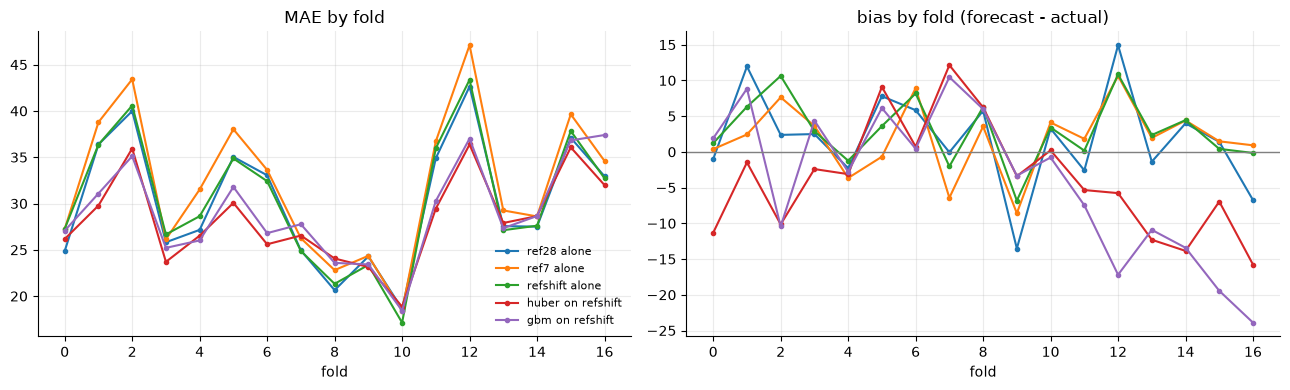

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in ["ref28 alone", "ref7 alone", "refshift alone", "huber on refshift", "gbm on refshift"]:
    axes[0].plot(FT[n]["MAE"], marker="o", ms=3, label=n); axes[1].plot(FT[n]["bias"], marker="o", ms=3, label=n)
axes[0].set_title("MAE by fold"); axes[1].set_title("bias by fold (forecast - actual)")
axes[1].axhline(0, color="grey", lw=1); axes[0].legend(frameon=False, fontsize=8)
for ax in axes: ax.set_xlabel("fold")
plt.tight_layout(); plt.show()

## Findings (09:00 cutoff, 17 folds; every method scored on the same 22,847 rows)

- **A faster reference level does not help as a forecast.** `ref7` alone is clearly worse than `ref28` (MAE +1.9, top-8 hit -0.05, bottom-8 -0.05): seven days of same-period prices are too noisy for the within-day shape. `refshift` (28-day shape moved to the last 7 days' level) is about equal to `ref28` (MAE +0.28, late folds +0.04, hit rates identical because the shift is constant within a day). It does remove the baseline's under-forecast in fold 16 (bias -0.15 against -6.7), so the level is better tracked, but the accuracy gain is nil.
- **The models do not improve with a better reference.** MAE difference to the 28-day baseline over all folds: Huber -1.90 (ref28), -1.82 (ref7), -1.91 (refshift); GBM -1.62, -1.58, -1.16. In the last four folds: Huber -0.24, +0.02, -0.13; GBM -0.07, +0.48, +1.27. So the gain on recent folds stays about zero, and GBM on `refshift` is worse in them.
- **The under-forecast is not caused by the reference.** In folds 13-16 the references alone have mean error -0.7 (`ref28`), +2.2 (`ref7`), +1.8 (`refshift`), but every model built on them has -12 to -16 (Huber) and -15.9 to -16.9 (GBM, `ref7`/`refshift`; -14.7 on `ref28`). The learned deviation from the reference is on average about 12-17 too negative in those folds. That means the weather/demand effect that the models learned from earlier months predicts lower prices than occurred in 2026, even when the reference is unbiased.
- **Against their own reference** the models add a lot when the reference is weak: Huber on `ref7` is 3.8 MAE better than `ref7` alone (late folds 1.7 better), top-8 hit +0.08, but that is mostly repairing `ref7`; relative to `ref28` the result is the same as before.
- **Hypotheses, not tested:** (a) the relationship between wind/demand/solar and price has shifted in 2026 (for instance through higher overall prices for the same weather); (b) one feature group, such as wind, drives most of the negative deviation; (c) the calendar/seasonal terms learned from summer 2025 double count what `ref28` already contains.
- **Next.** Find which feature group produces the negative deviation in the recent folds: re-run the Huber model on `ref28` with one group removed at a time (demand, wind, solar, seasonal terms, margin) and compare the late-fold bias and MAE; then recency weighting. If the weather relationship has genuinely shifted, an honest expectation for the hold-out is little or no gain over the baseline.
